In [0]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from delta.tables import DeltaTable
import matplotlib.pyplot as plt
import pandas as pd

CATALOG = "balaji_azure"
SCHEMA = "default"
PREFIX = f"{CATALOG}.{SCHEMA}"
BASE_PATH = "file:/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/Drafts"

spark.sql(f"USE CATALOG `{CATALOG}`")
spark.sql(f"USE SCHEMA `{SCHEMA}`")

def load_csv(name):
    pdf = pd.read_csv(f"{BASE_PATH}/{name}.csv")
    return spark.createDataFrame(pdf)

def load_json(name):
    pdf = pd.read_json(f"{BASE_PATH}/{name}.json", lines=True)
    return spark.createDataFrame(pdf)

def table(name):
    return spark.table(f"{PREFIX}.{name}")

readings = load_csv("water_meter_readings")
zones_raw = load_json("water_zones")
requests = load_csv("water_service_requests")
changes = load_csv("water_reading_changes")
incremental_staging = load_csv("water_readings_incremental")

zones = zones_raw.select(
    "zone_id",
    "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type",
    "daily_capacity_liters",
    "active",
    "commissioned_on"
)

def save_delta(df, name):
    (df.write.format("delta")
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .saveAsTable(f"{PREFIX}.{name}"))

save_delta(readings, "water_meter_readings_source")
save_delta(readings, "water_meter_readings_work")
save_delta(zones_raw, "water_zones_raw")
save_delta(zones, "water_zones")
save_delta(requests, "water_service_requests")
save_delta(changes, "water_reading_changes")
save_delta(incremental_staging, "water_readings_incremental_staging")

print("Source tables created.")
for name in [
    "water_meter_readings_source",
    "water_meter_readings_work",
    "water_zones_raw",
    "water_zones",
    "water_service_requests",
    "water_reading_changes",
    "water_readings_incremental_staging"
]:
    print(name, table(name).count())

readings = table("water_meter_readings_source")
zones = table("water_zones")
requests = table("water_service_requests")
changes = table("water_reading_changes")
incremental_staging = table("water_readings_incremental_staging")


Source tables created.
water_meter_readings_source 157
water_meter_readings_work 157
water_zones_raw 11
water_zones 11
water_service_requests 36
water_reading_changes 12
water_readings_incremental_staging 18


## Initial source validation

In [0]:
readings.printSchema()
zones.printSchema()
requests.printSchema()
changes.printSchema()
incremental_staging.printSchema()

print("Readings:", readings.count())
print("Zones:", zones.count())
print("Service requests:", requests.count())
print("Change records:", changes.count())
print("Incremental staging:", incremental_staging.count())
display(readings.limit(10))
display(zones)


root
 |-- reading_id: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: string (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: long (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)

root
 |-- request_id: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reported_at: string (nullable = true)
 |-- issue_type: string (nullable = true)
 |-- priority:

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway


zone_id,zone_name,city,district,zone_type,daily_capacity_liters,active,commissioned_on
W01,Old City,Hyderabad,Central,Residential,240000,true,2018-01-15
W02,Hill View,Hyderabad,North,Residential,180000,true,2019-02-15
W03,Market District,Hyderabad,Central,Commercial,210000,true,2020-03-15
W04,Lake Side,Hyderabad,West,Mixed,280000,true,2021-04-15
W05,University Quarter,Hyderabad,East,Institutional,150000,true,2022-05-15
W06,Industrial Estate,Hyderabad,South,Industrial,320000,true,2023-06-15
W07,Garden Colony,Hyderabad,North,Residential,190000,true,2024-07-15
W08,Transit Hub,Hyderabad,East,Commercial,170000,true,2018-08-15
W09,Riverfront,Hyderabad,West,Mixed,230000,true,2019-01-15
W10,South Extension,Hyderabad,South,Residential,260000,true,2020-02-15


## A. SQL Querying and Filtering

### 1. Inspect source, schema and count

In [0]:
readings.printSchema()
print("Row count:", readings.count())
display(readings)

root
 |-- reading_id: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: string (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: long (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

Row count: 157


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway


### 2. Valid readings with selected columns

In [0]:
display(readings.filter(F.col("reading_status") == "Valid").select("reading_id","meter_id","zone_id","reading_time","consumption_liters"))

reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01 07:00:00,2365
1002,M002,W02,2026-10-01 08:10:00,3545
1003,M003,W03,2026-10-01 09:20:00,548
1004,M004,W04,2026-10-01 10:00:00,2871
1006,M006,W06,2026-10-01 12:20:00,2171
1007,M007,W07,2026-10-01 13:00:00,4167
1008,M008,W08,2026-10-01 14:10:00,3621
1009,M009,W09,2026-10-01 15:20:00,1609
1010,M010,W10,2026-10-01 16:00:00,1829
1011,M011,W01,2026-10-02 07:10:00,313


### 3. Pressure below 2.5

In [0]:
display(readings.filter(F.col("pressure_bar") < 2.5).orderBy("pressure_bar"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08 07:10:00,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07 10:00:00,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03 10:20:00,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12 12:10:00,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14 09:00:00,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03 14:00:00,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04 08:10:00,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06 07:20:00,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06 08:00:00,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05 10:10:00,79.3,1.95,1.23,2661,Valid,SmartMeter


### 4. Flow 20–50 from Gateway or SmartMeter

In [0]:
display(readings.filter(F.col("flow_lpm").between(20,50) & F.col("source_system").isin("Gateway","SmartMeter")))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02 10:10:00,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02 13:10:00,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02 15:00:00,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03 08:00:00,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04 08:10:00,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05 13:10:00,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05 15:00:00,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05 16:10:00,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06 12:10:00,27.2,2.69,0.68,1131,Suspect,SmartMeter


### 5. Status counts

In [0]:
display(readings.groupBy("reading_status").count().orderBy("reading_status"))

reading_status,count
Rejected,9
Suspect,11
Valid,137


## B. Joins, Aggregations and Window Functions

### 6. Join readings with zone master

In [0]:
display(readings.join(zones,"zone_id","inner").select("zone_name","district","meter_id","consumption_liters"))

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


### 7. Unknown zone IDs

In [0]:
display(readings.join(zones.select("zone_id"),"zone_id","left_anti"))

zone_id,reading_id,meter_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
W99,1154,M999,2026-10-16 11:00:00,24.5,3.0,0.45,1150,Valid,FieldApp
null,1156,M012,2026-10-16 12:30:00,28.0,3.1,0.52,870,Valid,Gateway


### 8. Zones without meter readings

In [0]:
display(zones.join(readings.select("zone_id").distinct(),"zone_id","left_anti"))

zone_id,zone_name,city,district,zone_type,daily_capacity_liters,active,commissioned_on
W11,New Development,Hyderabad,West,Mixed,125000,false,2021-03-15


### 9. Valid consumption, pressure and counts by zone

In [0]:
zone_stats = (readings.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0)).groupBy("zone_id").agg(F.sum("consumption_liters").alias("total_consumption"),F.avg("pressure_bar").alias("average_pressure"),F.count("*").alias("reading_count")))
display(zone_stats.join(zones.select("zone_id","zone_name"),"zone_id","left"))

zone_id,total_consumption,average_pressure,reading_count,zone_name
W06,20212,3.160769230769231,13,Industrial Estate
W10,27808,3.717692307692307,14,South Extension
W07,25104,3.5700000000000003,13,Garden Colony
W08,33689,2.8657142857142857,14,Transit Hub
W02,24120,3.3061538461538458,13,Hill View
W03,35665,3.019999999999999,13,Market District
W99,1150,3.0,1,null
null,870,3.1,1,null
W04,20781,3.2371428571428575,14,Lake Side
W01,23107,3.423076923076923,13,Old City


### 10. Rank meters by consumption within district

In [0]:
meter_totals = (readings.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0)).join(zones.select("zone_id","district"),"zone_id","inner").groupBy("district","meter_id").agg(F.sum("consumption_liters").alias("total_consumption")))
ranked = meter_totals.withColumn("district_rank",F.dense_rank().over(Window.partitionBy("district").orderBy(F.desc("total_consumption"))))
display(ranked.orderBy("district","district_rank"))

district,meter_id,total_consumption,district_rank
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


## C. PySpark DataFrame Operations

### 11. Load and inspect DataFrames

In [0]:
readings = table("water_meter_readings_source")
zones = table("water_zones")
readings.printSchema()
zones.printSchema()

root
 |-- reading_id: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: string (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: long (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



### 12. High-flow Valid readings

In [0]:
display(readings.select("reading_id","meter_id","zone_id","flow_lpm","reading_status").filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60)).orderBy(F.desc("flow_lpm")))

reading_id,meter_id,zone_id,flow_lpm,reading_status
1110,M020,W10,84.0,Valid
1106,M016,W06,83.9,Valid
1083,M023,W03,83.9,Valid
1010,M010,W10,81.3,Valid
1013,M013,W03,80.7,Valid
1078,M018,W08,80.7,Valid
1093,M003,W03,80.4,Valid
1031,M001,W01,80.1,Valid
1123,M003,W03,79.7,Valid
1044,M014,W04,79.3,Valid


### 13. Flow category including nulls

In [0]:
flow_df = readings.withColumn("flow_category",F.when(F.col("flow_lpm").isNull(),"Unknown").when(F.col("flow_lpm") >= 60,"High").when(F.col("flow_lpm") >= 30,"Medium").otherwise("Low"))
display(flow_df)

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system,flow_category
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway,Medium
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter,Medium
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp,Low
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway,Medium
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter,High
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp,Medium
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway,High
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter,High
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp,Medium
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway,High


### 14. Average flow by zone type

In [0]:
display(readings.join(zones,"zone_id","inner").groupBy("zone_type").agg(F.avg("flow_lpm").alias("average_flow_lpm")))

zone_type,average_flow_lpm
Commercial,56.10000000000001
Residential,45.155737704918025
Mixed,38.165625
Industrial,43.14374999999999
Institutional,49.33125


### 15. Top three zones by valid consumption

In [0]:
top_zones = (readings.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0)).groupBy("zone_id").agg(F.sum("consumption_liters").alias("total_consumption")).orderBy(F.desc("total_consumption")).limit(3))
display(top_zones.join(zones.select("zone_id","zone_name"),"zone_id","left"))

zone_id,total_consumption,zone_name
W03,35665,Market District
W08,33689,Transit Hub
W05,28717,University Quarter


## D. Data Quality and Cleaning

### 16. Duplicate reading IDs and all duplicate rows

In [0]:
duplicate_ids = readings.groupBy("reading_id").count().filter(F.col("count") > 1).select("reading_id")
display(readings.join(duplicate_ids,"reading_id","inner").orderBy("reading_id","reading_time"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05 10:10:00,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16 13:00:00,36.0,3.2,0.8,1300,Valid,Gateway


### 17. Missing pressure or source-system values

In [0]:
missing = readings.filter(F.col("pressure_bar").isNull() | F.col("source_system").isNull())
print("Affected records:",missing.count())
display(missing)

Affected records: 2


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1153,M020,W10,2026-10-16 10:00:00,31.4,null,0.71,1020,Valid,Gateway
1155,M006,W06,2026-10-16 12:00:00,44.0,2.9,2.95,1560,Suspect,null


### 18. Invalid measurements

In [0]:
invalid = readings.filter((F.col("flow_lpm") < 0) | (F.col("consumption_liters") <= 0) | F.col("zone_id").isNull())
display(invalid)

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1151,M004,W04,2026-10-16 08:00:00,-12.5,2.8,0.62,500,Suspect,Gateway
1152,M015,W05,2026-10-16 09:00:00,22.0,2.1,0.5,0,Valid,SmartMeter
1156,M012,null,2026-10-16 12:30:00,28.0,3.1,0.52,870,Valid,Gateway


In [0]:
valid = readings.filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") > 0) & (F.col("consumption_liters") > 0) & F.col("zone_id").isNotNull() & F.col("pressure_bar").isNotNull())
w = Window.partitionBy("reading_id").orderBy(F.desc_nulls_last("reading_time"),F.desc_nulls_last("consumption_liters"),F.desc_nulls_last("flow_lpm"),F.asc_nulls_last("source_system"))
clean = valid.withColumn("rn",F.row_number().over(w)).filter(F.col("rn") == 1).drop("rn")
clean.write.format("delta").mode("overwrite").option("overwriteSchema","true").saveAsTable(f"{PREFIX}.water_readings_clean")
display(table("water_readings_clean"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway
1011,M011,W01,2026-10-02 07:10:00,13.0,4.39,0.66,313,Valid,SmartMeter


### 20. High-priority requests and average pressure

In [0]:
high_zones = requests.filter(F.col("priority") == "High").select("zone_id").distinct()
pressure_by_zone = readings.groupBy("zone_id").agg(F.avg("pressure_bar").alias("average_pressure"))
display(high_zones.join(pressure_by_zone,"zone_id","left").join(zones.select("zone_id","zone_name"),"zone_id","left"))

zone_id,average_pressure,zone_name
W06,3.2250000000000005,Industrial Estate
W10,3.7079999999999997,South Extension
W07,3.3706666666666667,Garden Colony
W08,2.92,Transit Hub
W02,3.3573333333333335,Hill View
W03,3.178,Market District
W04,3.2829411764705885,Lake Side
W01,3.437333333333333,Old City
W05,3.5,University Quarter
W09,3.6040000000000005,Riverfront


## E. Delta Lake Tables and CRUD

### 21. CTAS working-table copy

In [0]:
spark.sql(f"CREATE OR REPLACE TABLE {PREFIX}.water_readings_work_copy USING DELTA AS SELECT * FROM {PREFIX}.water_meter_readings_work")
print(table("water_readings_work_copy").count())

157


### 22. Insert two new readings with unique IDs


In [0]:
spark.sql(f"""INSERT INTO {PREFIX}.water_readings_work_copy VALUES
(900001,'M901','W01',TIMESTAMP '2026-10-21 09:00:00',42.0,3.2,0.5,2200,'Valid','Gateway'),
(900002,'M902','W02',TIMESTAMP '2026-10-21 10:00:00',35.0,3.0,0.4,1800,'Valid','SmartMeter')""")
display(table("water_readings_work_copy").filter(F.col("reading_id").isin(900001,900002)))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
900001,M901,W01,2026-10-21 09:00:00,42.0,3.2,0.5,2200,Valid,Gateway
900002,M902,W02,2026-10-21 10:00:00,35.0,3.0,0.4,1800,Valid,SmartMeter


### 23. Change one Suspect reading to Rejected

In [0]:
suspect = table("water_readings_work_copy").filter(F.col("reading_status") == "Suspect").select("reading_id").orderBy("reading_id").limit(1).collect()
if suspect:
    suspect_id = suspect[0]["reading_id"]
    spark.sql(f"UPDATE {PREFIX}.water_readings_work_copy SET reading_status='Rejected' WHERE reading_id={suspect_id}")
    display(table("water_readings_work_copy").filter(F.col("reading_id") == suspect_id))
else:
    print("No Suspect row available")

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Rejected,SmartMeter


### 24. Delete Rejected rows and compare counts

In [0]:
before_delete = table("water_readings_work_copy").count()
spark.sql(f"DELETE FROM {PREFIX}.water_readings_work_copy WHERE reading_status='Rejected'")
after_delete = table("water_readings_work_copy").count()
print("Before:",before_delete,"After:",after_delete,"Deleted:",before_delete-after_delete)

Before: 159 After: 149 Deleted: 10


### 25. Create zone consumption summary via DataFrame

In [0]:
summary = (table("water_readings_clean").groupBy("zone_id").agg(F.sum("consumption_liters").alias("total_consumption"),F.avg("pressure_bar").alias("average_pressure"),F.count("*").alias("reading_count")))
summary.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.zone_consumption_summary")
display(table("zone_consumption_summary"))

zone_id,total_consumption,average_pressure,reading_count
W06,20212,3.160769230769231,13
W10,26788,3.717692307692307,13
W07,25104,3.5700000000000003,13
W08,33689,2.8657142857142857,14
W02,24120,3.3061538461538458,13
W03,35665,3.019999999999999,13
W99,1150,3.0,1
W04,18120,3.336153846153846,13
W01,23107,3.423076923076923,13
W09,20894,3.5469230769230773,13


## F. MERGE, UPSERT and SCD

### 26. Separate matching and new change IDs

In [0]:
work = table("water_meter_readings_work")
matching = changes.join(work.select("reading_id"),"reading_id","inner")
new_rows = changes.join(work.select("reading_id"),"reading_id","left_anti")
print("Matching:",matching.count(),"New:",new_rows.count())
display(matching)
display(new_rows)

Matching: 6 New: 6


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01 11:10:00,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03 13:20:00,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07 08:10:00,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09 14:00:00,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12 15:10:00,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15 11:00:00,77.5,3.96,1.29,4908,Valid,FieldApp


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1201,M002,W02,2026-10-18 08:00:00,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18 09:00:00,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18 10:00:00,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18 11:00:00,38.1,2.9,0.6,1550,Valid,FieldApp
1205,M014,W04,2026-10-18 12:00:00,42.8,3.0,0.65,1700,Valid,FieldApp
1206,M017,W07,2026-10-18 13:00:00,47.5,3.1,0.7,1850,Valid,FieldApp


### 27. SQL MERGE SCD Type 1

In [0]:
spark.sql(f"""MERGE INTO {PREFIX}.water_meter_readings_work AS t
USING {PREFIX}.water_reading_changes AS s
ON t.reading_id = s.reading_id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *""")

DataFrame[num_affected_rows: bigint, num_updated_rows: bigint, num_deleted_rows: bigint, num_inserted_rows: bigint]

### 28. Verify changed and new IDs

In [0]:
display(table("water_meter_readings_work").join(changes.select("reading_id"),"reading_id","inner").orderBy("reading_id"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01 11:10:00,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03 13:20:00,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07 08:10:00,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09 14:00:00,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12 15:10:00,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15 11:00:00,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18 08:00:00,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18 09:00:00,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18 10:00:00,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18 11:00:00,38.1,2.9,0.6,1550,Valid,FieldApp


### 29. PySpark DeltaTable MERGE on a fresh copy

In [0]:

readings.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.water_meter_readings_work_pyspark")
target = DeltaTable.forName(spark,f"{PREFIX}.water_meter_readings_work_pyspark")
(target.alias("t").merge(changes.alias("s"),"t.reading_id = s.reading_id").whenMatchedUpdateAll().whenNotMatchedInsertAll().execute())
display(table("water_meter_readings_work_pyspark").join(changes.select("reading_id"),"reading_id","inner"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1005,M005,W05,2026-10-01 11:10:00,64.3,3.24,0.43,2776,Valid,FieldApp
1027,M027,W07,2026-10-03 13:20:00,54.6,4.99,0.95,2678,Valid,FieldApp
1062,M002,W02,2026-10-07 08:10:00,30.1,2.43,0.3,1057,Valid,FieldApp
1088,M028,W08,2026-10-09 14:00:00,81.4,2.17,1.06,4931,Valid,FieldApp
1119,M029,W09,2026-10-12 15:10:00,22.1,3.63,1.13,1339,Valid,FieldApp
1145,M025,W05,2026-10-15 11:00:00,77.5,3.96,1.29,4908,Valid,FieldApp
1201,M002,W02,2026-10-18 08:00:00,24.0,2.6,0.45,1100,Valid,FieldApp
1202,M005,W05,2026-10-18 09:00:00,28.7,2.7,0.5,1250,Valid,FieldApp
1203,M008,W08,2026-10-18 10:00:00,33.4,2.8,0.55,1400,Valid,FieldApp
1204,M011,W01,2026-10-18 11:00:00,38.1,2.9,0.6,1550,Valid,FieldApp


### 30. SCD Type 2 zone capacity history

In [0]:
history_base = zones.select("zone_id","zone_name","daily_capacity_liters",F.to_date("commissioned_on").alias("valid_from"),F.lit(None).cast("date").alias("valid_to"),F.lit(True).alias("is_current"))
history_base.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.zone_capacity_history")
history_table = DeltaTable.forName(spark,f"{PREFIX}.zone_capacity_history")
history_table.update(condition="zone_id IN ('W02','W06') AND is_current = true",set={"valid_to":F.lit("2026-10-19").cast("date"),"is_current":F.lit(False)})
new_capacities = (zones.filter(F.col("zone_id").isin("W02","W06")).select("zone_id","zone_name",F.when(F.col("zone_id")=="W02",195000).otherwise(305000).alias("daily_capacity_liters"),F.lit("2026-10-20").cast("date").alias("valid_from"),F.lit(None).cast("date").alias("valid_to"),F.lit(True).alias("is_current")))
new_capacities.write.format("delta").mode("append").saveAsTable(f"{PREFIX}.zone_capacity_history")
display(table("zone_capacity_history").filter(F.col("zone_id").isin("W02","W06")).orderBy("zone_id","valid_from"))

zone_id,zone_name,daily_capacity_liters,valid_from,valid_to,is_current
W02,Hill View,180000,2019-02-15,2026-10-19,false
W02,Hill View,195000,2026-10-20,null,true
W06,Industrial Estate,320000,2023-06-15,2026-10-19,false
W06,Industrial Estate,305000,2026-10-20,null,true


## G. Delta History, Time Travel and Maintenance

### 31. DESCRIBE DETAIL

In [0]:
display(spark.sql(f"DESCRIBE DETAIL {PREFIX}.water_meter_readings_work"))

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,3a60687b-1184-44d7-912d-b4706f5552e2,balaji_azure.default.water_meter_readings_work,null,abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/a0922c8c-58e6-420b-b537-c7711fe2e9ac,2026-11-11T07:06:25.663Z,2026-11-11T07:10:11.000Z,List(),List(),2,10120,"Map(delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, delta.enableRowTracking -> true, delta.checkpointPolicy -> v2, io.unitycatalog.tableId -> a0922c8c-58e6-420b-b537-c7711fe2e9ac, delta.rowTracking.materializedRowCommitVersionColumnName -> _row-commit-version-col-840504c6-d09f-464e-8efa-4963528de007, delta.rowTracking.materializedRowIdColumnName -> _row-id-col-2f4ebdb4-f271-44e6-bf16-8ff0ded7f3d9)",3,7,"List(appendOnly, clustering, deletionVectors, domainMetadata, invariants, rowTracking, v2Checkpoint)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",true


### 32. DESCRIBE HISTORY and MERGE version

In [0]:
delta_history = spark.sql(f"DESCRIBE HISTORY {PREFIX}.water_meter_readings_work")
display(delta_history)
merge_row = delta_history.filter(F.col("operation") == "MERGE").orderBy(F.desc("version")).first()
pre_merge_version = int(merge_row["version"])-1 if merge_row else None
print("Pre-MERGE version:",pre_merge_version)

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T07:10:11.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,MERGE,"Map(predicate -> [""(reading_id#49680L = reading_id#49690L)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}], clusteringOnWriteStatus -> null)",null,List(1947193299487452),8faedad0-489d-452b-bfe8-275705e01920,1111-050846-nro01ujp-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 4256, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 2746, materializeSourceTimeMs -> 2, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 896, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1825)",null,Databricks-Runtime/19.14.x-photon-scala2.13
0,2026-11-11T07:06:26.000Z,149309454107906,azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""databricks.internal.autoUpgrades.delta.enableRowTracking"":""true"",""delta.enableDeletionVectors"":""true"",""databricks.internal.autoUpgrades.delta.checkpointPolicy"":""v2"",""databricks.internal.autoUpgrades.delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version"":""2.12.0"",""delta.enableRowTracking"":""true"",""delta.checkpointPolicy"":""v2"",""io.unitycatalog.tableId"":""a0922c8c-58e6-420b-b537-c7711fe2e9ac"",""delta.rowTracking.materializedRowCommitVersionColumnName"":""_row-commit-version-col-840504c6-d09f-464e-8efa-4963528de007"",""delta.rowTracking.materializedRowIdColumnName"":""_row-id-col-2f4ebdb4-f271-44e6-bf16-8ff0ded7f3d9""}, statsOnLoad -> true, clusterByAuto -> true, clusteringOnWriteStatus -> Reason for skipping: Nonexistent clustering column, generally when replacing a Liquid table with a table without clustering columns)",null,List(1947193299487452),79edd438-6408-4e66-b8b6-4ac10c9f29a8,1111-050846-nro01ujp-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5864)",null,Databricks-Runtime/19.14.x-photon-scala2.13


Pre-MERGE version: 0


### 33. Time Travel and compare reading 1005

In [0]:
if pre_merge_version is not None:
    previous = spark.read.format("delta").option("versionAsOf",pre_merge_version).table(f"{PREFIX}.water_meter_readings_work")
    display(previous)
    before_1005 = previous.filter(F.col("reading_id")==1005).withColumn("snapshot",F.lit("Before MERGE"))
    after_1005 = table("water_meter_readings_work").filter(F.col("reading_id")==1005).withColumn("snapshot",F.lit("Current"))
    display(before_1005.unionByName(after_1005))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system,snapshot
1005,M005,W05,2026-10-01 11:10:00,61.8,3.04,0.43,2656,Suspect,SmartMeter,Before MERGE
1005,M005,W05,2026-10-01 11:10:00,64.3,3.24,0.43,2776,Valid,FieldApp,Current


### 34. OPTIMIZE and file counts


In [0]:
spark.read.csv(f"/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/water_meter_readings_work_copy.csv", header=True).write.mode("overwrite").saveAsTable(f"{PREFIX}.water_meter_readings_work_copy")
before_detail = spark.sql(f"DESCRIBE DETAIL {PREFIX}.water_meter_readings_work_copy").first()
print("Before:",before_detail["numFiles"])
display(spark.sql(f"OPTIMIZE {PREFIX}.water_meter_readings_work_copy"))
after_detail = spark.sql(f"DESCRIBE DETAIL {PREFIX}.water_meter_readings_work_copy").first()
print("After:",after_detail["numFiles"])

Before: 1


path,metrics
abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/aa9d95f0-2003-453c-bc6e-d1b23919a913,"List(0, 0, List(null, null, 0.0, 0, 0), List(null, null, 0.0, 0, 0), 0, null, null, 0, 0, 1, 1, true, 0, 0, 1794381517127, 1794381517703, 8, 0, null, List(0, 0), null, 10, 10, 0, 0, null, null, 0)"


After: 1


### 35. VACUUM dry run


In [0]:
display(spark.sql(f"VACUUM {PREFIX}.water_meter_readings_work_copy DRY RUN"))

path


## H. Unity Catalog, Views and Parquet

### 36. Catalog, schema and managed location

In [0]:
print("Catalog:",CATALOG,"Schema:",SCHEMA)
display(spark.sql(f"DESCRIBE DETAIL {PREFIX}.water_meter_readings_work"))

Catalog: balaji_azure Schema: default


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,3a60687b-1184-44d7-912d-b4706f5552e2,balaji_azure.default.water_meter_readings_work,null,abfss://unity-catalog-storage@dbstoragesd23buinind3a.dfs.core.windows.net/7405613151574717/__unitystorage/catalogs/cf9a2c09-1ac8-473b-a07d-5493da60eca2/tables/a0922c8c-58e6-420b-b537-c7711fe2e9ac,2026-11-11T07:06:25.663Z,2026-11-11T07:10:11.000Z,List(),List(),2,10120,"Map(delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, delta.enableRowTracking -> true, delta.checkpointPolicy -> v2, io.unitycatalog.tableId -> a0922c8c-58e6-420b-b537-c7711fe2e9ac, delta.rowTracking.materializedRowCommitVersionColumnName -> _row-commit-version-col-840504c6-d09f-464e-8efa-4963528de007, delta.rowTracking.materializedRowIdColumnName -> _row-id-col-2f4ebdb4-f271-44e6-bf16-8ff0ded7f3d9)",3,7,"List(appendOnly, clustering, deletionVectors, domainMetadata, invariants, rowTracking, v2Checkpoint)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",true


### 37. Permanent view of Valid readings with zone names

In [0]:
spark.sql(f"""CREATE OR REPLACE VIEW {PREFIX}.valid_water_readings_view AS
SELECT r.*, z.zone_name, z.district
FROM {PREFIX}.water_meter_readings_source r
INNER JOIN {PREFIX}.water_zones z ON r.zone_id=z.zone_id
WHERE r.reading_status='Valid' AND r.flow_lpm>0 AND r.consumption_liters>0""")
display(table("valid_water_readings_view"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system,zone_name,district
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway,Old City,Central
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter,Hill View,North
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp,Market District,Central
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway,Lake Side,West
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp,Industrial Estate,South
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway,Garden Colony,North
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter,Transit Hub,East
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp,Riverfront,West
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway,South Extension,South
1011,M011,W01,2026-10-02 07:10:00,13.0,4.39,0.66,313,Valid,SmartMeter,Old City,Central


### 38. Temporary low-pressure view

In [0]:
readings.filter(F.col("pressure_bar") < 2.5).createOrReplaceTempView("low_pressure_readings")
display(spark.sql("SELECT * FROM low_pressure_readings"))

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway
1016,M016,W06,2026-10-02 12:00:00,12.9,2.26,0.72,613,Valid,Gateway
1018,M018,W08,2026-10-02 14:20:00,70.5,2.09,0.3,3709,Valid,FieldApp
1024,M024,W04,2026-10-03 10:20:00,44.5,1.83,1.25,2085,Valid,FieldApp
1028,M028,W08,2026-10-03 14:00:00,15.0,1.9,0.94,452,Valid,Gateway
1031,M001,W01,2026-10-04 07:00:00,80.1,2.38,1.21,3504,Valid,Gateway
1032,M002,W02,2026-10-04 08:10:00,34.4,1.92,0.88,1006,Valid,SmartMeter
1033,M003,W03,2026-10-04 09:20:00,56.6,2.19,1.24,2184,Valid,FieldApp
1036,M006,W06,2026-10-04 12:20:00,26.2,2.09,0.56,1065,Valid,FieldApp


### 39. Global temporary High-priority requests view

Global temporary views persist across sessions in the same Spark application, where supported.

In [0]:
requests.filter(F.col("priority") == "High").createOrReplaceTempView("high_priority_water_requests")
display(spark.sql("SELECT * FROM high_priority_water_requests"))

request_id,meter_id,zone_id,reported_at,issue_type,priority,estimated_cost,work_status
5001,M001,W01,2026-10-02 08:00:00,Low Pressure,High,13627.01,In Progress
5004,M022,W02,2026-10-08 11:00:00,Water Quality,High,6315.27,In Progress
5007,M013,W03,2026-10-14 14:00:00,Leak Suspected,High,16135.29,In Progress
5010,M004,W04,2026-10-20 10:00:00,Valve Inspection,High,10011.1,In Progress
5013,M025,W05,2026-10-07 13:00:00,Meter Fault,High,11268.95,In Progress
5016,M016,W06,2026-10-13 09:00:00,Low Pressure,High,17897.18,In Progress
5019,M007,W07,2026-10-19 12:00:00,Water Quality,High,6952.65,In Progress
5022,M028,W08,2026-10-06 08:00:00,Leak Suspected,High,14519.05,In Progress
5025,M019,W09,2026-10-12 11:00:00,Valve Inspection,High,3322.05,In Progress
5028,M010,W10,2026-10-18 14:00:00,Meter Fault,High,1827.17,In Progress


### 40. Parquet to Delta table

In [0]:
parquet_path = f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/water_clean_parquet"
table("water_readings_clean").write.mode("overwrite").parquet(parquet_path)
parquet_read = spark.read.parquet(parquet_path)
parquet_read.printSchema()
parquet_read.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.water_readings_from_parquet")
display(table("water_readings_from_parquet"))

root
 |-- reading_id: long (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: string (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: long (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)



reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01 07:00:00,39.1,3.56,0.75,2365,Valid,Gateway
1002,M002,W02,2026-10-01 08:10:00,59.9,4.6,0.39,3545,Valid,SmartMeter
1003,M003,W03,2026-10-01 09:20:00,25.7,2.22,1.15,548,Valid,FieldApp
1004,M004,W04,2026-10-01 10:00:00,56.7,2.84,1.1,2871,Valid,Gateway
1006,M006,W06,2026-10-01 12:20:00,35.8,2.52,1.2,2171,Valid,FieldApp
1007,M007,W07,2026-10-01 13:00:00,65.0,3.19,0.67,4167,Valid,Gateway
1008,M008,W08,2026-10-01 14:10:00,70.3,3.39,0.54,3621,Valid,SmartMeter
1009,M009,W09,2026-10-01 15:20:00,30.8,4.57,1.05,1609,Valid,FieldApp
1010,M010,W10,2026-10-01 16:00:00,81.3,2.38,0.33,1829,Valid,Gateway
1011,M011,W01,2026-10-02 07:10:00,13.0,4.39,0.66,313,Valid,SmartMeter


## I. Structured Streaming

### 41. Streaming rate source at five rows per second

In [0]:
rate_stream = spark.readStream.format("rate").option("rowsPerSecond",5).option("checkpointLocation", f"/Workspace/Users/azuser7399_mml.local@karthikirisoutlook.onmicrosoft.com/Drafts").load()
print(rate_stream.isStreaming)
import uuid
display(rate_stream, checkpointLocation=f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/rate_stream_display/{uuid.uuid4()}")

True
Checkpointing to /Volumes/balaji_azure/default/tp_files/checkpoints/rate_stream_display/21396de3-ca52-4726-8827-ff428383a7a2


### 42. Simulated meter ID and flow

In [0]:
meter_stream = rate_stream.withColumn("meter_id",F.concat(F.lit("M"),F.lpad((F.pmod(F.col("value"),20)+1).cast("string"),3,"0"))).withColumn("flow_lpm",F.pmod(F.col("value")*7,100).cast("double"))
import uuid
display(meter_stream, checkpointLocation=f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/meter_stream_display/{uuid.uuid4()}")

Checkpointing to /Volumes/balaji_azure/default/tp_files/checkpoints/meter_stream_display/cc49237e-498d-4748-8623-0ea158ad2ca3


### 43. Filter flow above 60 L/min

In [0]:
high_flow_stream = meter_stream.filter(F.col("flow_lpm") > 60)
import uuid
display(high_flow_stream, checkpointLocation=f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/high_flow_stream_display/{uuid.uuid4()}")

Checkpointing to /Volumes/balaji_azure/default/tp_files/checkpoints/high_flow_stream_display/9efb761e-b3af-4d0e-ab05-64061ee1c2cb


### 44. Aggregate flow category with memory sink

In [0]:
stream_categories = meter_stream.withColumn("flow_category",F.when(F.col("flow_lpm")>=60,"High").when(F.col("flow_lpm")>=30,"Medium").otherwise("Low"))
stream_counts = stream_categories.groupBy("flow_category").count()
import uuid
stream_query = (stream_counts.writeStream.format("memory").queryName("water_flow_counts").outputMode("complete").trigger(availableNow=True).option("checkpointLocation", f"/Volumes/{CATALOG}/{SCHEMA}/tp_files/checkpoints/water_flow_counts/{uuid.uuid4()}").start())
stream_query.processAllAvailable()
display(spark.sql("SELECT * FROM water_flow_counts"))

flow_category,count
Low,2


### 45. Stop streaming query



In [0]:
stream_query.stop()
print("Stopped:",not stream_query.isActive)

Stopped: True


## J. Lakeflow / Delta Live Tables

### 46. SQL Bronze streaming table


In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE water_bronze_readings
AS
SELECT *
FROM STREAM(balaji_azure.default.water_meter_readings_source);

CREATE OR REFRESH STREAMING TABLE water_silver_readings
AS
SELECT *
FROM STREAM(water_bronze_readings)
WHERE reading_status = 'Valid'
  AND flow_lpm > 0
  AND consumption_liters > 0
  AND zone_id IS NOT NULL;

CREATE OR REFRESH MATERIALIZED VIEW water_gold_zone_summary
AS
SELECT
    zone_id,
    SUM(consumption_liters) AS total_consumption_liters,
    AVG(pressure_bar) AS average_pressure_bar,
    COUNT(*) AS reading_count
FROM water_silver_readings
GROUP BY zone_id;


result
The operation was successfully executed.


### 50. Python Lakeflow pipeline


In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F

@dp.table(name="water_bronze_readings_py")
def water_bronze_readings_py():
    return spark.readStream.table(
        "balaji_azure.default.water_meter_readings_source"
    )


@dp.table(name="water_silver_readings_py")
def water_silver_readings_py():
    return (
        spark.readStream.table("water_bronze_readings_py")
        .filter(
            (F.col("reading_status") == "Valid") &
            (F.col("flow_lpm") > 0) &
            (F.col("consumption_liters") > 0) &
            F.col("zone_id").isNotNull()
        )
    )


@dp.materialized_view(name="water_gold_zone_summary_py")
def water_gold_zone_summary_py():
    return (
        spark.read.table("water_silver_readings_py")
        .groupBy("zone_id")
        .agg(
            F.sum("consumption_liters").alias("total_consumption_liters"),
            F.avg("pressure_bar").alias("average_pressure_bar"),
            F.count("*").alias("reading_count")
        )
    )


## K. Incremental Loads, Analytics and Visualizations

### 51. Append staged incremental readings after initial pipeline update



In [0]:
staging = table("water_readings_incremental_staging")
print("Staging rows:",staging.count())
display(staging)


Staging rows: 18


reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19 07:00:00,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19 08:00:00,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19 09:00:00,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19 10:00:00,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19 11:00:00,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19 12:00:00,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20 07:00:00,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20 08:00:00,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20 09:00:00,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20 10:00:00,37.7,2.94,0.87,1510,Valid,SmartMeter


### 52. Refresh pipeline and verify Gold


In [0]:

display(spark.table(f"{PREFIX}.water_gold_zone_summary"))

zone_id,total_consumption_liters,average_pressure_bar,reading_count
W06,20212,3.160769230769231,13
W10,27808,3.717692307692307,14
W07,25104,3.5700000000000003,13
W08,33689,2.8657142857142857,14
W02,24120,3.3061538461538458,13
W03,35665,3.019999999999999,13
W99,1150,3.0,1
W04,20781,3.2371428571428575,14
W01,23107,3.423076923076923,13
W09,20894,3.5469230769230773,13


### Visualization setup — use Matplotlib for Exercises 53–54


In [0]:
viz_valid = table("water_readings_clean").join(zones.select("zone_id","zone_name","district"),"zone_id","inner")

### 53. Bar chart by zone and pie chart by district

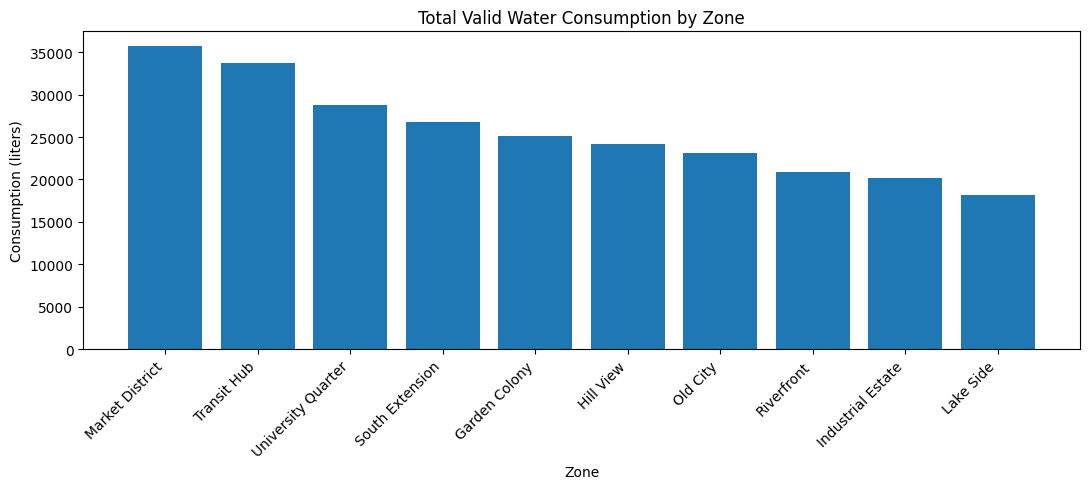

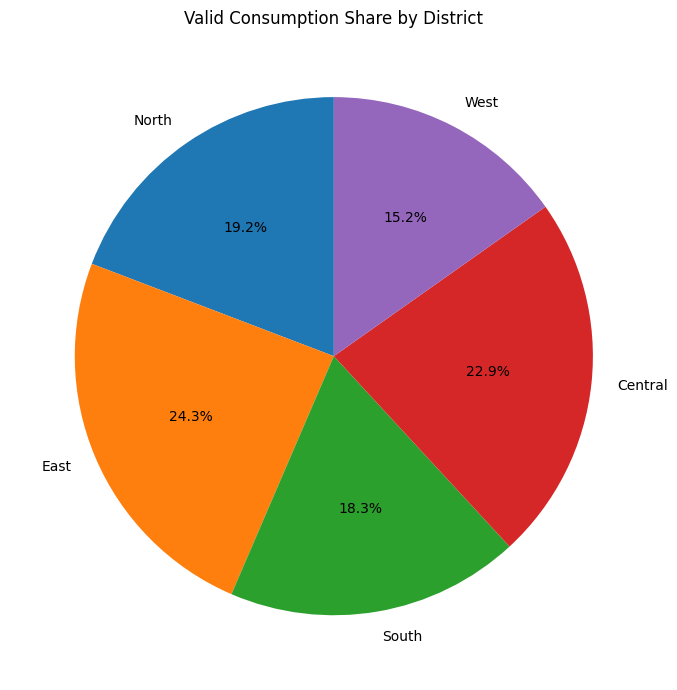

In [0]:
zone_pd = (viz_valid.groupBy("zone_name").agg(F.sum("consumption_liters").alias("consumption")).orderBy(F.desc("consumption"))).toPandas()
plt.figure(figsize=(11,5))
plt.bar(zone_pd["zone_name"],zone_pd["consumption"])
plt.title("Total Valid Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Consumption (liters)")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

district_pd = viz_valid.groupBy("district").agg(F.sum("consumption_liters").alias("consumption")).toPandas()
plt.figure(figsize=(7,7))
plt.pie(district_pd["consumption"],labels=district_pd["district"],autopct="%1.1f%%",startangle=90)
plt.title("Valid Consumption Share by District")
plt.tight_layout()
plt.show()

### 54. Daily line chart and pressure–flow scatter plot

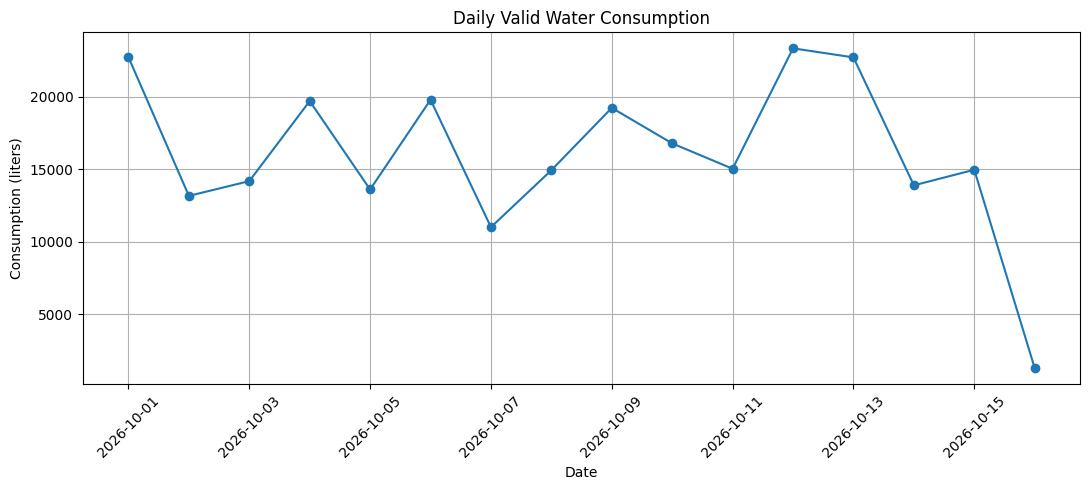

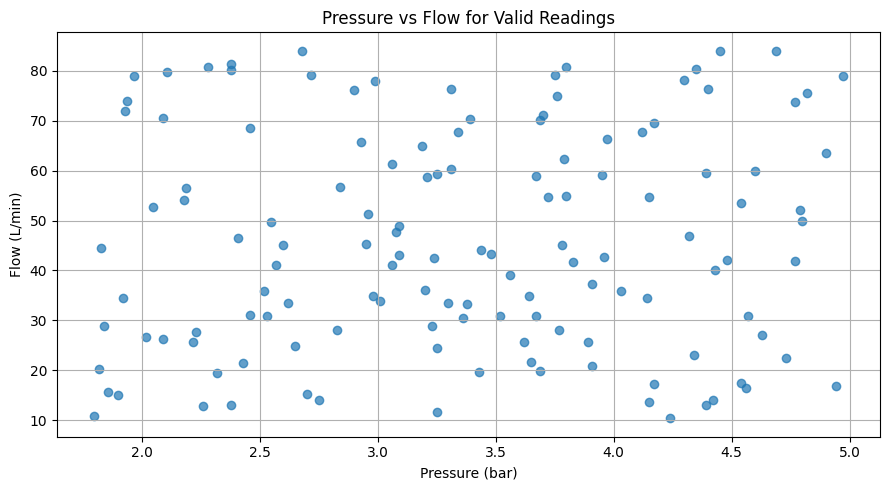

In [0]:
daily_pd = (viz_valid.withColumn("reading_date",F.to_date("reading_time")).groupBy("reading_date").agg(F.sum("consumption_liters").alias("consumption")).orderBy("reading_date")).toPandas()
plt.figure(figsize=(11,5))
plt.plot(daily_pd["reading_date"],daily_pd["consumption"],marker="o")
plt.title("Daily Valid Water Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (liters)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

scatter_pd = viz_valid.filter(F.col("pressure_bar").isNotNull()).select("pressure_bar","flow_lpm").toPandas()
plt.figure(figsize=(9,5))
plt.scatter(scatter_pd["pressure_bar"],scatter_pd["flow_lpm"],alpha=0.7)
plt.title("Pressure vs Flow for Valid Readings")
plt.xlabel("Pressure (bar)")
plt.ylabel("Flow (L/min)")
plt.grid(True)
plt.tight_layout()
plt.show()

### 55. Final water operations dashboard

In [0]:
zone_report = (viz_valid.groupBy("zone_id","zone_name","district").agg(F.sum("consumption_liters").alias("total_consumption"),F.avg("pressure_bar").alias("average_pressure"),F.avg("chlorine_mg_l").alias("average_chlorine"),F.count("*").alias("valid_readings")))
request_report = requests.groupBy("zone_id").agg(F.count("*").alias("service_requests"),F.sum(F.when(F.col("priority")=="High",1).otherwise(0)).alias("high_priority_requests"))
dashboard = zone_report.join(request_report,"zone_id","left").fillna({"service_requests":0,"high_priority_requests":0})
display(dashboard.orderBy(F.desc("high_priority_requests"),F.asc("average_pressure")))
dashboard.write.format("delta").mode("overwrite").saveAsTable(f"{PREFIX}.water_operations_dashboard")
print("Zones with lowest average pressure:")
display(dashboard.orderBy("average_pressure").limit(3))
print("Zones with most High-priority requests:")
display(dashboard.orderBy(F.desc("high_priority_requests")).limit(3))

zone_id,zone_name,district,total_consumption,average_pressure,average_chlorine,valid_readings,service_requests,high_priority_requests
W02,Hill View,North,24120,3.3061538461538458,0.6192307692307693,13,4,2
W01,Old City,Central,23107,3.423076923076923,0.8200000000000002,13,4,2
W08,Transit Hub,East,33689,2.8657142857142857,0.6185714285714284,14,4,1
W03,Market District,Central,35665,3.019999999999999,0.936153846153846,13,3,1
W06,Industrial Estate,South,20212,3.160769230769231,0.6776923076923076,13,4,1
W04,Lake Side,West,18120,3.336153846153846,0.7861538461538461,13,3,1
W09,Riverfront,West,20894,3.5469230769230773,0.6815384615384615,13,4,1
W07,Garden Colony,North,25104,3.5700000000000003,0.773076923076923,13,3,1
W05,University Quarter,East,28717,3.632857142857143,0.8735714285714286,14,4,1
W10,South Extension,South,26788,3.717692307692307,0.7992307692307692,13,3,1


Zones with lowest average pressure:


zone_id,zone_name,district,total_consumption,average_pressure,average_chlorine,valid_readings,service_requests,high_priority_requests
W08,Transit Hub,East,33689,2.8657142857142857,0.6185714285714284,14,4,1
W03,Market District,Central,35665,3.019999999999999,0.936153846153846,13,3,1
W06,Industrial Estate,South,20212,3.160769230769231,0.6776923076923076,13,4,1


Zones with most High-priority requests:


zone_id,zone_name,district,total_consumption,average_pressure,average_chlorine,valid_readings,service_requests,high_priority_requests
W02,Hill View,North,24120,3.3061538461538458,0.6192307692307693,13,4,2
W01,Old City,Central,23107,3.423076923076923,0.8200000000000002,13,4,2
W06,Industrial Estate,South,20212,3.160769230769231,0.6776923076923076,13,4,1
